In [1]:
import time
import random
import pandas as pd
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import Select
from bs4 import BeautifulSoup

def count_all_countries_cyber_incidents():
    options = webdriver.ChromeOptions()
    options.add_argument("--start-maximized")
    
    wd = webdriver.Chrome(options=options)
    url = "https://www.cfr.org/cyber-operations/"
    wd.get(url)
    time.sleep(5) # 첫 페이지 로딩 대기
    
    # 1. 드롭다운 요소에서 나라 이름 목록 미리 확보하기
    sponsor_dropdown = wd.find_element(By.CSS_SELECTOR, '[class*="field-operators"] select, [class*="state-sponsor"] select')
    select_sponsor = Select(sponsor_dropdown)
    
    # 드롭다운에 있는 모든 국가 텍스트 추출 (빈 값이나 안내 문구 제외)
    countries = [opt.text.strip() for opt in select_sponsor.options 
                 if opt.text.strip() and "Select" not in opt.text and "All" not in opt.text]
    
    print(f"🌍 총 {len(countries)}개의 국가 필터를 발견했습니다. 분석을 시작합니다.\n")
    
    # 결과를 담을 리스트
    summary_result = []
    
    # 2. 각 국가별로 루프 돌면서 카운트 채취
    for country in countries:
        try:
            print(f"▶ [{country}] 사건 개수 집계 중...")
            
            # 페이지가 바뀌면서 엘리먼트가 깨질 수 있으므로 루프마다 새로 잡아줍니다.
            dropdown = wd.find_element(By.CSS_SELECTOR, '[class*="field-operators"] select, [class*="state-sponsor"] select')
            select_element = Select(dropdown)
            
            # 국가 선택
            select_element.select_by_visible_text(country)
            time.sleep(random.randint(3, 4)) # 필터링 로딩 대기
            
            # BeautifulSoup으로 현재 결과 페이지 파싱
            html = wd.page_source
            soup = BeautifulSoup(html, 'html.parser')
            
            # 사건 게시물 링크 패턴 찾아 개수 세기
            post_elements = soup.select('.field-content.cst-issue.views-field-title a')
            incident_count = len(post_elements)
            
            print(f"   -> 발견된 사건 수: {incident_count}개")
            
            # 결과 저장
            summary_result.append({
                "Country": country,
                "Incident_Count": incident_count
            })
            
        except Exception as e:
            print(f"❌ [{country}] 처리 중 오류 발생: {e}")
            continue
            
    # 3. 브라우저 종료 및 결과 저장
    wd.quit()
    
    # 데이터프레임 변환 및 CSV 저장
    result_df = pd.DataFrame(summary_result)
    result_df = result_df.sort_values(by="Incident_Count", ascending=False) # 많은 순으로 정렬
    
    output_filename = "cfr_cyber_incidents_by_country.csv"
    result_df.to_csv(output_filename, index=False, encoding='utf-8-sig')
    
    print("\n==========================================")
    print(f"🎉 모든 국가 순회 완료! 결과가 '{output_filename}'에 저장되었습니다.")
    print("==========================================")
    print(result_df)

# 함수 실행
count_all_countries_cyber_incidents()

InvalidSessionIdException: Message: invalid session id: session deleted as the browser has closed the connection
from disconnected: not connected to DevTools
  (Session info: chrome=150.0.7871.114); For documentation on this error, please visit: https://www.selenium.dev/documentation/webdriver/troubleshooting/errors#invalidsessionidexception
Stacktrace:
	chromedriver!GetHandleVerifier [0x7ff76291a865+152a5]
	chromedriver!GetHandleVerifier [0x7ff76291a8c0+15300]
	chromedriver!(No symbol) [0x7ff76247596d]
	chromedriver!(No symbol) [0x7ff762461132]
	chromedriver!(No symbol) [0x7ff76248706c]
	chromedriver!(No symbol) [0x7ff762500430]
	chromedriver!(No symbol) [0x7ff76251d5b2]
	chromedriver!(No symbol) [0x7ff7624c2b3c]
	chromedriver!(No symbol) [0x7ff7624c3a53]
	chromedriver!GetHandleVerifier [0x7ff762efd3a1+5f7de1]
	chromedriver!GetHandleVerifier [0x7ff762ef7a3b+5f247b]
	chromedriver!GetHandleVerifier [0x7ff762f1bca5+6166e5]
	chromedriver!GetHandleVerifier [0x7ff7629372ae+31cee]
	chromedri

In [ ]:
import pandas as pd
import folium
import requests

# 1. 크롤링해서 만든 CSV 데이터 불러오기
df = pd.read_csv('cfr_cyber_incidents_by_country.csv')

# 드롭다운 전체 선택 항목('- Any -') 제거
df = df[df['Country'] != '- Any -']

# 🌟 [영어 이름 통일] GeoJSON(세계지도 파일) 표준 영어 이름 규칙에 완벽 맞춤
name_mapping = {
    'Russian Federation': 'Russia',
    'United States': 'United States of America',
    'United States of America': 'United States of America',
    "Korea (Democratic People's Republic of)": 'North Korea',
    'Korea (Republic of)': 'South Korea',
    'Iran (Islamic Republic of)': 'Iran',
    'Syrian Arab Republic': 'Syria',       
    'Hong Kong': 'China',                  
    'Palestine, State of': 'Palestine'
}

df['Country'] = df['Country'].replace(name_mapping)

# 동일 국가 데이터 합산 (China + Hong Kong 등)
df = df.groupby('Country', as_index=False)['Incident_Count'].sum()

# 2. 세계 지도 경계선 데이터(GeoJSON) 가져오기
geojson_url = 'https://raw.githubusercontent.com/python-visualization/folium/master/examples/data/world-countries.json'
world_geo = requests.get(geojson_url).json()

# 3. 기본 세계 지도 생성
m = folium.Map(location=[30, 10], zoom_start=2, tiles='OpenStreetMap')

# 4. 🔥 핵심: Choropleth로 지도 색상 칠하기
# (여기서 칠해지는 기본 레이어 이름을 영어 표준으로 매핑해둔 상태야)
choropleth = folium.Choropleth(
    geo_data=world_geo,             
    name='cyber_incidents',
    data=df,                        
    columns=['Country', 'Incident_Count'], 
    key_on='feature.properties.name', 
    fill_color='Reds',              
    fill_opacity=0.7,               
    line_opacity=0.2,               
    legend_name='Cyber Incident Count', # 범례 제목도 영어로 통일!
    nan_fill_color='white'          
).add_to(m)

# 5. 🌟 [인터랙티브 영어 툴팁 추가]
# 마우스를 올렸 때 GeoJSON에 내장된 '영어 국가명(name)'이 팝업으로 뜨도록 결합해주는 서브 레이어 코드야.
folium.GeoJson(
    world_geo,
    style_function=lambda feature: {
        'fillColor': '#ffffff', 
        'color': 'black', 
        'weight': 0, 
        'fillOpacity': 0
    }, # Choropleth 색상을 가리지 않게 투명하게 설정
    tooltip=folium.GeoJsonTooltip(
        fields=['name'],              # GeoJSON 안에 들어있는 영문 국가명 필드 선언
        aliases=['Country: '],        # 라벨 이름도 영어로 깔끔하게!
        localize=True,
        sticky=False,
        labels=True,
        style=""""
            background-color: #F0F2F5;
            border: 2px solid black;
            border-radius: 3px;
            box-shadow: 3px;
        """
    )
).add_to(m)

# 6. 결과를 HTML 파일로 저장
m.save('world_cyber_incidents_map_en.html')
print("🎉 영문 이름 통일 및 영어 툴팁 기능이 적용된 세계 지도가 완성되었습니다!")

🎉 영문 이름 통일 및 영어 툴팁 기능이 적용된 세계 지도가 완성되었습니다!


In [ ]:
import pandas as pd
import folium

# 1. 아까 크롤링해서 만든 CSV 데이터 불러오기
df = pd.read_csv('cfr_cyber_incidents_by_country.csv')

# 2. 🌍 주요 국가들의 중심 위도/경도 좌표 사전 (데이터에 맞춰 자동 매핑)
# CFR 데이터에 나오는 국가 이름에 맞춰 좌표를 추가해두었어.
country_coordinates = {
    'Russian Federation': [61.5240, 105.3188],
    'Russia': [61.5240, 105.3188],
    'China': [35.8617, 104.1954],
    'United States': [37.0902, -95.7129],
    'Republic of Korea': [35.9078, 127.7669],
    "Korea (Democratic People's Republic of)": [40.3399, 127.5101],
    'Iran': [32.4279, 53.6880],
    'United Kingdom': [55.3781, -3.4360],
    'Israel': [31.0461, 34.8516],
    'Ukraine': [48.3794, 31.1656],
    # 만약 결과에 다른 나라가 더 있다면 여기에 [위도, 경도]를 추가해주면 돼!
}

# 3. 기본 세계 지도 생성 (배경은 깔끔하게 어두운 Dark 모드로 하면 빨간 원이 더 잘 보여!)
# 일반 지도를 원하면 tiles='OpenStreetMap'으로 바꾸면 돼.
m = folium.Map(location=[30, 10], zoom_start=2, tiles='CartoDB dark_matter')

# 4. 🔥 핵심 로직: 국가별로 돌면서 점(CircleMarker) 찍기
for idx, row in df.iterrows():
    country_name = row['Country']
    count = row['Incident_Count']
    
    # 0개인 국가는 점을 찍지 않고 패스
    if count == 0:
        continue
        
    # 해당 국가의 좌표 정보가 사전에 있는지 확인
    if country_name in country_coordinates:
        lat, lon = country_coordinates[country_name]
        
        # [수식 튜닝] 사건 개수에 따라 원의 반지름(radius)을 결정해.
        # 개수가 너무 적으면 원이 안 보이니까 기본 크기(5)에 개수별 가중치(count * 1.5)를 더해줬어.
        circle_radius = 5 + (count * 1.5) 
        
        # 지도 위에 버블 점 찍기
        folium.CircleMarker(
            location=[lat, lon],
            radius=circle_radius,            # 🔴 사건 개수에 따라 동적으로 변하는 원의 크기
            popup=f"<b>{country_name}</b><br>사건 수: {count}건", # 클릭 시 뜨는 문구
            tooltip=f"{country_name}: {count}건",                 # 마우스 올리면 뜨는 문구
            color='#FF0000',                 # 원의 테두리 색상 (강렬한 빨강)
            fill=True,                       # 안쪽 채우기 여부
            fill_color='#FF3333',            # 안쪽 채우기 색상 (약간 밝은 빨강)
            fill_opacity=0.6,                # 겹치는 원들을 보기 위해 투명도 조절
            weight=1.5                       # 테두리 두께
        ).add_to(m)

# 5. 결과를 HTML 파일로 저장
m.save('world_cyber_incidents_bubble_map.html')
print("🎉 점 크기 분포도(world_cyber_incidents_bubble_map.html) 파일 생성 완료!")

🎉 점 크기 분포도(world_cyber_incidents_bubble_map.html) 파일 생성 완료!


In [ ]:
import pandas as pd

In [ ]:
cot_df = pd.read_csv("./midterm/cot_나라4개합친거.csv")

In [ ]:
cot_df['Description'].head()

0    Teamviewer, a German-based company that makes ...
1    The Polish deputy minister of digital affairs ...
2    Cloudfare?셲 security team identified a phishin...
3    FlyingYeti is a threat actor known primarily f...
4    UAC-0188 is a Russian threat actor that has be...
Name: Description, dtype: object

In [ ]:
mi_df = pd.read_csv("./midterm/group_technique_country.csv")

In [ ]:
mi_df['relationship_description'].head()

0    [Indrik Spider](https://attack.mitre.org/group...
1    [LuminousMoth](https://attack.mitre.org/groups...
2    [Medusa Group](https://attack.mitre.org/groups...
3    [Wizard Spider](https://attack.mitre.org/group...
4    [FIN7](https://attack.mitre.org/groups/G0046) ...
Name: relationship_description, dtype: object

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# -------------------------------------------------------------------
# [사전 준비] COT 데이터의 국가 이름 표준화 작업 (이전 단계에서 했던 것)
# -------------------------------------------------------------------
cfr_name_map = {
    'Russian Federation': 'Russia',
    'United States': 'United States of America',
    'United States of America': 'United States of America',
    "Korea (Democratic People's Republic of)": 'North Korea',
    'Korea (Republic of)': 'South Korea',
    'Iran (Islamic Republic of)': 'Iran',
    'Syrian Arab Republic': 'Syria',       
    'Hong Kong': 'China',
}
cot_df['Country'] = cot_df['State_sponsor'].replace(cfr_name_map)


# -------------------------------------------------------------------
# 1단계: 텍스트 데이터 전처리 및 벡터화 (TF-IDF)
# -------------------------------------------------------------------
# 결측치(NaN)가 있으면 문자열 변환 시 에러가 나므로 빈 문자열('')로 대체합니다.
cot_corpus = cot_df['Description'].fillna('').astype(str).tolist()
mi_corpus = mi_df['relationship_description'].fillna('').astype(str).tolist()

# 영어 불용어(the, an 등)를 제외하고 단어 벡터화 도구 선언
vectorizer = TfidfVectorizer(stop_words='english')

# 두 텍스트 데이터를 통합하여 거대한 전체 단어 사전을 학습(Fit)시킵니다.
vectorizer.fit(cot_corpus + mi_corpus)

# 각각의 문장들을 숫자로 이루어진 행렬(Vector)로 변환(Transform)합니다.
cot_matrix = vectorizer.transform(cot_corpus)
mi_matrix = vectorizer.transform(mi_corpus)


# -------------------------------------------------------------------
# 2단계: ⚡ 초고속 행렬 연산으로 코사인 유사도 바둑판 생성
# -------------------------------------------------------------------
# 결과물인 sim_matrix는 (COT 행 개수 x MITRE 행 개수) 크기의 거대한 유사도 지도입니다.
sim_matrix = cosine_similarity(cot_matrix, mi_matrix)


# -------------------------------------------------------------------
# 3단계: 유사도가 높은 매칭 결과 솎아내기 (국가 라벨 이식 준비)
# -------------------------------------------------------------------
matched_results = []
similarity_threshold = 0.5  # 🌟 매칭 기준선: 50% 이상 닮은 문맥만 인정 (필요시 0.4나 0.6으로 조절)

for cot_idx in range(sim_matrix.shape[0]):
    # 현재 COT 사건 하나에 대해 가장 높은 유사도 점수를 가진 MITRE의 인덱스를 찾습니다.
    best_mi_idx = np.argmax(sim_matrix[cot_idx])
    best_score = sim_matrix[cot_idx][best_mi_idx]
    
    # 임계치(0.5)를 넘긴 매칭 건만 저장
    if best_score >= similarity_threshold:
        matched_results.append({
            'mi_index': best_mi_idx,
            'matched_country': cot_df.iloc[cot_idx]['Country'],  # COT의 배후 국가 정보
            'similarity_score': best_score
        })

# 4단계: 매칭 데이터를 데이터프레임으로 변환 후 정리
match_bridge_df = pd.DataFrame(matched_results)

# 동일한 MITRE 기법에 여러 COT 사건이 매칭될 수 있으므로, 유사도 점수가 가장 높은 국가 1개만 남깁니다.
match_bridge_df = match_bridge_df.sort_values(by='similarity_score', ascending=False).drop_duplicates(subset=['mi_index'])


# -------------------------------------------------------------------
# 5단계: 🎉 MI_DF에 유사도 기반 매칭 국가 최종 주입!
# -------------------------------------------------------------------
# MITRE 데이터프레임의 고유 인덱스를 기준으로 매칭된 국가를 복사해 옵니다.
mi_df['Matched_Country_by_NLP'] = mi_df.index.map(match_bridge_df.set_index('mi_index')['matched_country'])

# 매칭 결과 확인용 출력
print("=== 🤖 텍스트 유사도 매칭 완료! ===")
print(mi_df['Matched_Country_by_NLP'].value_counts(dropna=False))

=== 🤖 텍스트 유사도 매칭 완료! ===
Matched_Country_by_NLP
NaN       4545
Russia       1
Name: count, dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. ⚙️ 실제 올려주신 파일 이름으로 정확히 로드
cot_df = pd.read_csv('./midterm/cot_나라4개합친거.csv')
mi_df = pd.read_csv('./midterm/group_technique_country_final.csv')

# 2. 🌍 COT 데이터의 'State_sponsor' 국가 이름 표준화
name_mapping = {
    'Russian Federation': 'Russia',
    'Iran (Islamic Republic of)': 'Iran',
    "Korea (Democratic People's Republic of)": 'North Korea',
    'Korea (Republic of)': 'South Korea',
}
cot_df['State_sponsor'] = cot_df['State_sponsor'].replace(name_mapping)

# 3. 🔤 결측치 제거 및 텍스트 벡터화
cot_corpus = cot_df['Description'].fillna('').astype(str).tolist()
mi_corpus = mi_df['relationship_description'].fillna('').astype(str).tolist()

vectorizer = TfidfVectorizer(stop_words='english')
vectorizer.fit(cot_corpus + mi_corpus)

cot_matrix = vectorizer.transform(cot_corpus)
mi_matrix = vectorizer.transform(mi_corpus)

# 4. ⚡ 코사인 유사도 연산 (바둑판 매트릭스 생성)
sim_matrix = cosine_similarity(cot_matrix, mi_matrix)

# 5. 🎯 [논리 변경] 임계치 제거 -> 각 MITRE 기법별로 '가장 유사도가 높은 COT 사건'의 국가를 무조건 매칭
matched_countries = []

# sim_matrix의 열(Column) 개수는 mi_df의 행 개수와 같습니다.
for mi_idx in range(sim_matrix.shape[1]):
    # 해당 MITRE 기법과 모든 COT 사건들 중 가장 점수가 높은 COT 인덱스를 찾습니다.
    best_cot_idx = np.argmax(sim_matrix[:, mi_idx])
    best_score = sim_matrix[best_cot_idx][mi_idx]
    
    # 0점인 경우는 단어가 단 하나도 안 겹치는 경우이므로 제외하고, 0점보다 크면 무조건 매칭합니다.
    if best_score > 0:
        matched_country = cot_df.iloc[best_cot_idx]['State_sponsor']
        matched_countries.append(matched_country)
    else:
        matched_countries.append(np.nan) # 완전히 무관한 경우만 NaN

# 6. 🎉 mi_df에 최종 매칭 국가 컬럼 주입
mi_df['Matched_Country_by_NLP'] = matched_countries

# 7. 최종 결과 확인
print("=== 🤖 실제 파일 기준 유사도 매칭 완료! ===")
print(mi_df['Matched_Country_by_NLP'].value_counts(dropna=False))

=== 🤖 실제 파일 기준 유사도 매칭 완료! ===
Matched_Country_by_NLP
China                          2019
Russia                         1140
North Korea                     707
Iran                            674
Belarus: Russian Federation       5
China: Russian Federation         1
Name: count, dtype: int64


In [ ]:
mi_df.to_csv('group_technique_n.csv')

In [ ]:
df = pd.read_csv('cfr_cyber_incidents_by_country.csv')

In [ ]:
df['Incident_Count'].sum()

np.int64(1670)

In [ ]:
import time
import random
import csv
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import Select
from bs4 import BeautifulSoup

def crawl_all_countries_except_major_four():
    options = webdriver.ChromeOptions()
    options.add_argument("--start-maximized")
    
    # 1. 브라우저 실행 및 사이트 접속
    wd = webdriver.Chrome(options=options)
    url = "https://www.cfr.org/cyber-operations/"
    wd.get(url)
    time.sleep(5) # 첫 페이지 완전 로딩 대기
    
    # 2. 드롭다운 요소에서 전체 국가 목록 미리 확보하기
    sponsor_dropdown = wd.find_element(By.CSS_SELECTOR, '[class*="field-operators"] select, [class*="state-sponsor"] select')
    select_sponsor = Select(sponsor_dropdown)
    
    # 드롭다운의 기본 안내 문구(- Any -, Select 등) 제외하고 순수 국가명만 추출
    all_countries = [opt.text.strip() for opt in select_sponsor.options 
                     if opt.text.strip() and "Select" not in opt.text and "All" not in opt.text and "- Any -" not in opt.text]
    
    # 🚨 [핵심 필터] 이미 수집 완료된 '북한, 중국, 러시아, 이란' 제외 리스트 생성
    exclude_countries = [
        "China", 
        "Russian Federation", 
        "Iran (Islamic Republic of)", 
        "Korea (Democratic People's Republic of)"
    ]
    
    target_countries = [c for c in all_countries if c not in exclude_countries]
    
    print(f"🌍 발견된 전체 국가 필터: {len(all_countries)}개")
    print(f"🚫 제외된 국가: {exclude_countries}")
    print(f"🎯 수집 대상 국가: {len(target_countries)}개\n")
    
    # 3. 저장할 CSV 파일 열기 및 헤더 작성
    output_filename = "cot_remaining_countries_incidents.csv"
    
    with open(output_filename, mode='w', encoding='utf-8-sig', newline='') as f:
        writer = csv.writer(f)
        # 국가 식별을 위해 "State_sponsor" 컬럼을 추가했습니다.
        writer.writerow(["Title", "URL", "Description", "Details(Meta)", "State_sponsor"])
        
        # 4. 각 국가별로 루프를 돌며 수집 시작
        for c_idx, country in enumerate(target_countries, 1):
            print(f"\n==================================================")
            print(f"🔄 [{c_idx}/{len(target_countries)}] {country} 필터 적용 및 링크 수집 시작")
            print(f"==================================================")
            
            try:
                # 페이지가 리프레시되면서 엘리먼트가 무효화(Stale)되는 것을 방지하기 위해 매번 새로 탐색합니다.
                dropdown = wd.find_element(By.CSS_SELECTOR, '[class*="field-operators"] select, [class*="state-sponsor"] select')
                select_element = Select(dropdown)
                
                # 국가 선택 후 로딩 대기
                select_element.select_by_visible_text(country)
                time.sleep(random.randint(3, 4))
                
                # 현재 필터링된 결과 화면 파싱
                html = wd.page_source
                soup = BeautifulSoup(html, 'html.parser')
                post_elements = soup.select('.field-content.cst-issue.views-field-title a')
                
                post_list = []
                for post in post_elements:
                    title = post.get_text(strip=True)
                    link = post.get('href')
                    if link and not link.startswith('http'):
                        link = "https://www.cfr.org" + link
                    post_list.append({"title": title, "link": link})
                
                print(f" └ 발견된 사건 수: {len(post_list)}개")
                
                # 5. 수집된 링크를 순회하며 상세 페이지 본문 긁어오기
                for idx, item in enumerate(post_list, 1):
                    title = item['title']
                    url = item['link']
                    print(f"   ➔ 상세 수집 중 [{idx}/{len(post_list)}]: {title[:40]}...")
                    
                    try:
                        # 상세 페이지 이동
                        wd.get(url)
                        time.sleep(random.randint(2, 4)) # 차단 방지용 랜덤 대기
                        
                        detail_html = wd.page_source
                        detail_soup = BeautifulSoup(detail_html, 'html.parser')
                        
                        # 본문 추출 (p 태그들 결합)
                        p_tags = detail_soup.select('.article-body p, .field-name-body p, .content p')
                        description = "\n".join([p.get_text(strip=True) for p in p_tags])
                        
                        if not description:
                            description = "본문 텍스트를 찾을 수 없습니다."
                            
                        # 메타 데이터 추출
                        meta_sections = detail_soup.select('.field, .row, [class*="field-name-field-"]')
                        meta_details = []
                        for meta in meta_sections:
                            meta_text = meta.get_text(": ", strip=True)
                            if meta_text and ":" in meta_text and len(meta_text) < 200:
                                meta_details.append(meta_text)
                        meta_summary = " | ".join(list(set(meta_details)))
                        
                        # 데이터 저장 (마지막에 현재 크롤링 중인 국가명 기록)
                        writer.writerow([title, url, description, meta_summary, country])
                        
                    except Exception as detail_e:
                        print(f"   ❌ 상세 페이지 오류 ({title}): {detail_e}")
                        writer.writerow([title, url, "상세 정보 크롤링 실패", str(detail_e), country])
                        
                # 한 국가의 수집이 끝나면 메인 주소로 돌아와서 다음 국가를 고를 준비를 합니다.
                wd.get("https://www.cfr.org/cyber-operations/")
                time.sleep(3)
                
            except Exception as country_e:
                print(f"❌ 국가 [{country}] 처리 중 치명적 오류 발생: {country_e}")
                wd.get("https://www.cfr.org/cyber-operations/")
                time.sleep(3)
                continue

    # 6. 종료
    wd.quit()
    print(f"\n🎉 북중러이를 제외한 전 세계 국가 사건 수집 및 통합 완료!")
    print(f"💾 최종 결과 저장 파일: {output_filename}")

# 실행
crawl_all_countries_except_major_four()

🌍 발견된 전체 국가 필터: 51개
🚫 제외된 국가: ['China', 'Russian Federation', 'Iran (Islamic Republic of)', "Korea (Democratic People's Republic of)"]
🎯 수집 대상 국가: 47개


🔄 [1/47] Australia 필터 적용 및 링크 수집 시작
 └ 발견된 사건 수: 4개
   ➔ 상세 수집 중 [1/4]: Targeting of Islamic State group militan...
   ➔ 상세 수집 중 [2/4]: Australian Signals Directorate...
   ➔ 상세 수집 중 [3/4]: Operations against actors targeting Aust...
   ➔ 상세 수집 중 [4/4]: Compromise of Yandex...

🔄 [2/47] Bahrain 필터 적용 및 링크 수집 시작
 └ 발견된 사건 수: 1개
   ➔ 상세 수집 중 [1/1]: Targeting of Bahraini activists with Peg...

🔄 [3/47] Belarus 필터 적용 및 링크 수집 시작
 └ 발견된 사건 수: 5개
   ➔ 상세 수집 중 [1/5]: Targeting of Ukrainian state entities...
   ➔ 상세 수집 중 [2/5]: Targeting of Ukrainian and Polish milita...
   ➔ 상세 수집 중 [3/5]: Targeting of Ukrainian government websit...
   ➔ 상세 수집 중 [4/5]: Targeting of Polish members of parliamen...
   ➔ 상세 수집 중 [5/5]: UNC1151...

🔄 [4/47] Bulgaria 필터 적용 및 링크 수집 시작
 └ 발견된 사건 수: 1개
   ➔ 상세 수집 중 [1/1]: Disruption of NetWalker ransomware...

🔄 [5/47]

In [ ]:
import re

In [ ]:
def parse_metadata(raw_text):
    # 결측치(NaN)이거나 텍스트가 아닌 경우 빈 딕셔너리 반환
    if not isinstance(raw_text, str):
        return {}
        
    junk_text = "Map: Timeline: Glossary: Methodology: Report an Incident"
    clean_text = raw_text.replace(junk_text, "")
    
    tags = [
        "Suspected state sponsor", "Type of incident", "Target category",
        "Suspected victims", "Date of report", "Affiliations",
        "Victim government reaction", "Policy response", "Read more" 
    ]
    
    pattern = r"(" + "|".join(tags) + r")\s*:\s*"
    parts = re.split(pattern, clean_text)
    
    parsed_data = {}
    
    for i in range(1, len(parts) - 1, 2):
        key = parts[i].strip()
        value = parts[i+1]
        value = re.sub(r"^[ :|]+|[ :|]+$", "", value)
        
        if key != "Read more":
            parsed_data[key] = value.strip()
            
    return parsed_data

# 2. 데이터 불러오기
main_df = pd.read_csv('./cot_remaining_countries_incidents.csv')

# 3. 'Details(Meta)' 컬럼 전체에 파싱 함수 적용
# 각 행마다 딕셔너리 형태로 변환된 데이터가 들어갑니다.
parsed_series = main_df['Details(Meta)'].apply(parse_metadata)

# 4. 딕셔너리의 Key들을 각각의 컬럼(Column)으로 변환 (Pandas의 마법!)
meta_df = pd.json_normalize(parsed_series)

# 5. 기존 DataFrame과 새로 만든 컬럼들 합치기
# 필요 없는 기존 'Details(Meta)' 컬럼은 삭제(drop)합니다.
final_all_df = pd.concat([main_df.drop('Details(Meta)', axis=1), meta_df], axis=1)

# 6. 결과 확인
final_all_df.head()

,Title,URL,Description,State_sponsor,Victim government reaction,Policy response,Suspected state sponsor,Type of incident,Target category,Date of report,Affiliations,Suspected victims
0,Targeting of Islamic State group militants in ...,https://www.cfr.org/cyber-operations/targeting...,"In 2016, Australian operators deployed the too...",Australia,Unknown,Unknown: Suspected state sponsor response: Con...,Australia,Sabotage,Military,Jun 2023,Australian Signals Directorate,Islamic State militants operating around the c...
1,Australian Signals Directorate,https://www.cfr.org/cyber-operations/australia...,Responsible for attacking infrastructure that ...,Australia,NaN,NaN,Australia,Data destruction,Private sector,Apr 2020 | | Suspected state sponsor response...,NaN,NaN
2,Operations against actors targeting Australian...,https://www.cfr.org/cyber-operations/operation...,The Australian government launched cyberattack...,Australia,NaN,NaN,Australia,Data destruction,Private sector,Apr 2020,Australian Signals Directorate | Suspected sta...,Infrastructure used by foreign-based cybercrim...
3,Compromise of Yandex,https://www.cfr.org/cyber-operations/compromis...,"This threat actor deployed Regin, a rare type ...",Australia,Yes,Confirmation,Australia: Canada: New Zealand: United Kingdom...,Espionage,Private sector,Jun 2019,Five Eyes,Yandex
4,Targeting of Bahraini activists with Pegasus s...,https://www.cfr.org/cyber-operations/targeting...,The Bahraini government used NSO Group’s Pegas...,Bahrain,Unknown,NaN,Bahrain,Espionage,Civil society,Feb 2022,Believed to be the work of Bahrain's government,"Bahraini activists, including a lawyer, an onl..."


In [ ]:
final_all_df.to_csv("cot_all.csv")

In [ ]:
main_df = pd.read_csv('./midterm/cot_나라4개합친거.csv')

In [ ]:
final_all_df.head()

,Title,URL,Description,State_sponsor,Victim government reaction,Policy response,Suspected state sponsor,Type of incident,Target category,Date of report,Affiliations,Suspected victims
0,Targeting of Islamic State group militants in ...,https://www.cfr.org/cyber-operations/targeting...,"In 2016, Australian operators deployed the too...",Australia,Unknown,Unknown: Suspected state sponsor response: Con...,Australia,Sabotage,Military,Jun 2023,Australian Signals Directorate,Islamic State militants operating around the c...
1,Australian Signals Directorate,https://www.cfr.org/cyber-operations/australia...,Responsible for attacking infrastructure that ...,Australia,NaN,NaN,Australia,Data destruction,Private sector,Apr 2020 | | Suspected state sponsor response...,NaN,NaN
2,Operations against actors targeting Australian...,https://www.cfr.org/cyber-operations/operation...,The Australian government launched cyberattack...,Australia,NaN,NaN,Australia,Data destruction,Private sector,Apr 2020,Australian Signals Directorate | Suspected sta...,Infrastructure used by foreign-based cybercrim...
3,Compromise of Yandex,https://www.cfr.org/cyber-operations/compromis...,"This threat actor deployed Regin, a rare type ...",Australia,Yes,Confirmation,Australia: Canada: New Zealand: United Kingdom...,Espionage,Private sector,Jun 2019,Five Eyes,Yandex
4,Targeting of Bahraini activists with Pegasus s...,https://www.cfr.org/cyber-operations/targeting...,The Bahraini government used NSO Group’s Pegas...,Bahrain,Unknown,NaN,Bahrain,Espionage,Civil society,Feb 2022,Believed to be the work of Bahrain's government,"Bahraini activists, including a lawyer, an onl..."


In [ ]:
integrated_df = pd.concat([main_df, final_all_df], ignore_index=True)

In [ ]:
integrated_df.head()

,Title,URL,Description,Date_of_report,State_sponsor,Affiliations,Type_of_incident,Target_category,Suspected_victims,Victim_government_reaction,Policy_response,technique_id,Victim government reaction,Policy response,Suspected state sponsor,Type of incident,Target category,Date of report,Suspected victims
0,"Targeting of Teamviewer, a German-based compan...",https://www.cfr.org/cyber-operations/targeting...,"Teamviewer, a German-based company that makes ...",2024-06,Russian Federation,APT 29,Espionage,Private sector,"Teamviewer, a German-based company that makes ...",Unknown,Unknown,T1020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"Targeting of TVP, a public service broadcaster...",https://www.cfr.org/cyber-operations/targeting...,The Polish deputy minister of digital affairs ...,2024-06,Russian Federation,Believed to be affiliated with the Russian gov...,Denial of service,Civil society,Polish public broadcaster TVP,Unknown,Confirmation,T1498,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Targeting of Ukrainian citizens who were conce...,https://www.cfr.org/cyber-operations/targeting...,Cloudfare?셲 security team identified a phishin...,2024-05,Russian Federation,FlyingYeti,Espionage,Civil society,Ukrainian citizens,Yes,Confirmation: Suspected state sponsor response...,T1020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,FlyingYeti,https://www.cfr.org/cyber-operations/flyingyeti,FlyingYeti is a threat actor known primarily f...,2024-05,Russian Federation,Believed to be affiliated with the Russian gov...,Espionage,Civil society: Military,Ukrainian military entities and Ukrainian citi...,Unknown,Confirmation: Suspected state sponsor response...,T1020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,UAC-0188,https://www.cfr.org/cyber-operations/uac-0188,UAC-0188 is a Russian threat actor that has be...,2024-05,Russian Federation,Believed to be affiliated with the Russian gov...,Espionage,Private sector,U.S. and European financial and insurance inst...,Yes,Confirmation: Suspected state sponsor response...,T1020,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
import pandas as pd

# 1. 실제 올려주신 파일명으로 데이터 로드 (환경에 맞게 변수명을 매칭하세요)
# 예: main_df = pd.read_csv('cot_나라4개합친거.csv')
#     final_all_df = pd.read_csv('cot_all.csv')

# 2. 🛡️ 기존 데이터에서 'technique_id' 컬럼 완전히 제거 (제외하기)
if 'technique_id' in main_df.columns:
    main_df = main_df.drop(columns=['technique_id'])
    print("▶ main_df에서 technique_id 컬럼을 정상적으로 제외했습니다.")

if 'technique_id' in final_all_df.columns:
    final_all_df = final_all_df.drop(columns=['technique_id'])
    print("▶ final_all_df에서 technique_id 컬럼을 정상적으로 제외했습니다.")

# 3. 🌍 양쪽 데이터프레임의 국가 컬럼명 정제 및 표준화
# cot_all.csv는 'State_sponsor'를 사용하므로, 혹시 다른 컬럼명으로 되어 있다면 맞춰줍니다.
if 'Country' in final_all_df.columns:
    final_all_df = final_all_df.rename(columns={'Country': 'State_sponsor'})
if 'Country' in main_df.columns:
    main_df = main_df.rename(columns={'Country': 'State_sponsor'})

# 4. 🔥 컬럼이 똑같아진 두 판을 세로로 깔끔하게 묶기 (concat)
integrated_df = pd.concat([main_df, final_all_df], ignore_index=True)

# 5. 📊 병합 결과물 검수 및 국가별 데이터 개수 확인
print("\n=== 🌍 병합 및 통합 완료 후 국가별 사건 분포 ===")
print(integrated_df['State_sponsor'].value_counts(dropna=False))

# 6. 💾 최종 마스터본을 엑셀과 CSV 파일로 각각 안전하게 저장
integrated_df.to_excel('cot_master_integrated.xlsx', index=False, engine='openpyxl')
integrated_df.to_csv('cot_all_n.csv', index=False, encoding='utf-8-sig')

print("\n🎉 'technique_id'가 제외된 전 세계 국가 통합 마스터 파일(cot_master_integrated.xlsx) 저장 완료!")


=== 🌍 병합 및 통합 완료 후 국가별 사건 분포 ===
State_sponsor
China                                      265
Russian Federation                         188
Iran (Islamic Republic of)                 110
Korea (Democratic People's Republic of)    106
United States                               19
Pakistan                                    17
Vietnam                                     11
India                                       11
United Arab Emirates                         8
Saudi Arabia                                 7
Israel                                       6
Belarus                                      5
Palestine, State of                          5
Ukraine                                      5
China: Russian Federation                    4
Australia                                    4
United Kingdom                               4
Mexico                                       4
Korea (Republic of)                          3
Canada                                       3
United State

In [ ]:
!pip install --upgrade nbformat


   ---------------------------------------- 0/6 [fastjsonschema]
   ------------- -------------------------- 2/6 [referencing]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   -------------------------- ------------- 4/6 [jsonschema]
   --------------------------------- ------ 5/6 [nbformat]
   --------------------------------- ------ 5/6 [nbformat]
   --------------------------------- ------ 5/6 [nbformat]
   --------------------------------- ------ 5/6 [nbformat]
   ---------------------------------------- 6/6 [nbformat]



In [ ]:
import sys
!{sys.executable} -m pip install --upgrade nbformat

In [9]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ==========================================
# [1단계] 데이터 전처리 및 무결성 확보
# ==========================================
data_file = './midterm/group_technique_country.csv' 
df = pd.read_csv(data_file, encoding='utf-8')

# 결측치 및 Unknown 제거
df_filtered = df[df['Country'].notna() & (df['Country'] != 'Unknown')].copy()

country_mapping = {
    'North Korea': '북한', 'DPRK': '북한', '북한': '북한',
    'China': '중국', '중국': '중국',
    'Russia': '러시아', '러시아': '러시아',
    'Iran': '이란', '이란': '이란'
}

# 국가 이름 표준화 및 유효 국가 필터링
df_filtered['Normalized_Country'] = df_filtered['Country'].map(country_mapping)
df_target = df_filtered[df_filtered['Normalized_Country'].notna()].copy()

# A. 국가별, 공격기법별 고유 해커 그룹 수 집계 (nunique)
technique_counts = df_target.groupby(['Normalized_Country', 'technique_name'])['group_id'].nunique().reset_index()
technique_counts.rename(columns={'group_id': 'using_groups'}, inplace=True)


# ==========================================
# [2단계] 🔥 [완벽 해결 포인트] Top 5 컷오프 후 지분율 계산
# ==========================================
# 1. 국가별로 사용 그룹 수가 많은 순서대로 전체 데이터를 정렬합니다.
df_sorted = technique_counts.sort_values(by=['Normalized_Country', 'using_groups'], ascending=[True, False])

# 2. 비율 계산 전에, 순수 개수 기준으로 각 국가별 Top 5 기법을 먼저 슬라이싱합니다.
df_top5 = df_sorted.groupby('Normalized_Country').head(5).reset_index(drop=True)

# 3. 분모 정의: 잘라낸 상위 5개 기법들의 'using_groups 총합'을 국가별 분모로 잡습니다.
# 이렇게 해야 이 5개 조각을 다 더했을 때 그래프에서 정확히 100%가 구현됩니다.
top5_total_by_country = df_top5.groupby('Normalized_Country')['using_groups'].sum()

# 4. 상위 5개 기법 내에서의 정확한 상대적 지분율(%) 계산
df_top5['usage_percentage'] = (df_top5['using_groups'] / df_top5['Normalized_Country'].map(top5_total_by_country)) * 100

# 최종 컬럼명 한글화
df_top5.columns = ['국가', '공격기법명', '사용그룹수', '사용비율(%)']


# ==========================================
# [3단계] 에러 없는 완벽한 Plotly 차트 시각화
# ==========================================

# 차트 1: 누적 막대 차트 (Stacked Bar Chart - 이제 무조건 100% 최고점에 안착합니다)
fig_stacked = px.bar(
    df_top5, 
    x="국가", 
    y="사용비율(%)", 
    color="공격기법명",
    title="국가별 주요 APT 공격 기법 Top 5 비교 (누적 지분율)",
    text="사용비율(%)"
)
fig_stacked.update_traces(texttemplate='%{text:.1f}%', textposition='inside')
fig_stacked.update_layout(xaxis_title="국가", yaxis_title="상대적 사용비율 (%)", barmode='stack')
fig_stacked.show()


# 차트 2: 그룹 막대 차트 (Grouped Bar Chart)
fig_grouped = px.bar(
    df_top5, 
    x="공격기법명", 
    y="사용비율(%)", 
    color="국가",
    title="공격 기법별 국가간 비중 비교 (그룹)",
    barmode="group"
)
fig_grouped.update_layout(xaxis_title="공격 기법", yaxis_title="사용비율 (%)")
fig_grouped.show()


# 차트 3: 국가별 도넛 차트 서브플롯 (Pie/Donut Subplots - 한 파이가 완벽한 100%를 이룹니다)
countries = df_top5["국가"].unique()
fig_pie = make_subplots(
    rows=2, cols=2, 
    specs=[[{'type':'domain'}, {'type':'domain'}], [{'type':'domain'}, {'type':'domain'}]],
    subplot_titles=countries
)

for i, country in enumerate(countries):
    country_df = df_top5[df_top5["국가"] == country]
    row = (i // 2) + 1
    col = (i % 2) + 1
    
    fig_pie.add_trace(
        go.Pie(
            labels=country_df["공격기법명"], 
            values=country_df["사용비율(%)"], 
            name=country,
            hole=0.4
        ),
        row=row, col=col
    )

fig_pie.update_layout(title_text="국가별 Top 5 공격 기법 지분율 (도넛 차트)")
fig_pie.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. ⚙️ 실제 올려주신 파일 이름으로 정확히 로드
cot_df = pd.read_csv('./midterm/cot_나라4개합친거.csv')
mi_df = pd.read_csv('./midterm/group_technique_country_final.csv')

# 2. 🌍 COT 데이터의 'State_sponsor' 국가 이름 표준화
name_mapping = {
    'Russian Federation': 'Russia',
    'Iran (Islamic Republic of)': 'Iran',
    "Korea (Democratic People's Republic of)": 'North Korea',
    'Korea (Republic of)': 'South Korea',
}
cot_df['State_sponsor'] = cot_df['State_sponsor'].replace(name_mapping)

# 3. 🔤 결측치 제거 및 텍스트 벡터화
cot_corpus = cot_df['Description'].fillna('').astype(str).tolist()
mi_corpus = mi_df['relationship_description'].fillna('').astype(str).tolist()

vectorizer = TfidfVectorizer(stop_words='english')
vectorizer.fit(cot_corpus + mi_corpus)

cot_matrix = vectorizer.transform(cot_corpus)
mi_matrix = vectorizer.transform(mi_corpus)

# 4. ⚡ 코사인 유사도 연산 (바둑판 매트릭스 생성)
sim_matrix = cosine_similarity(cot_matrix, mi_matrix)

# ==========================================
# 5. 🎯 [변경 구간] 기존 Country를 새 컬럼으로 복사 후 결측치만 채우기
# ==========================================
# 먼저 기존 Country 컬럼의 데이터를 그대로 복사하여 새로운 'Final_Country' 컬럼을 생성합니다.
mi_df['Final_Country'] = mi_df['Country']

for mi_idx in range(sim_matrix.shape[1]):
    # 새로 만든 컬럼(Final_Country)의 값이 비어있는(NaN) 경우에만 처리합니다.
    if pd.isna(mi_df.at[mi_idx, 'Final_Country']):
        
        # 유사도 분석을 통해 가장 점수가 높은 COT 인덱스를 찾습니다.
        best_cot_idx = np.argmax(sim_matrix[:, mi_idx])
        best_score = sim_matrix[best_cot_idx][mi_idx]
        
        # 단어가 하나라도 겹치는 경우(0점보다 큰 경우)에만 국가를 채워 넣습니다.
        if best_score > 0:
            matched_country = cot_df.iloc[best_cot_idx]['State_sponsor']
            mi_df.at[mi_idx, 'Final_Country'] = matched_country
        # 0점인 경우는 기존에 NaN이었으므로 그대로 매칭 없이 유지됩니다.

# 6. 🎉 최종 결과 확인 및 비교
print("=== 🤖 기존 데이터 보존 및 결측치 유사도 매칭 완료! ===")
print("\n[원본 Country 컬럼 분포]")
print(mi_df['Country'].value_counts(dropna=False))

print("\n[유사도로 결측치를 채운 Final_Country 컬럼 분포]")
print(mi_df['Final_Country'].value_counts(dropna=False))
mi_df.to_csv('group_technique_n.csv', index=False, encoding='utf-8-sig')

=== 🤖 기존 데이터 보존 및 결측치 유사도 매칭 완료! ===

[원본 Country 컬럼 분포]
Country
NaN            1776
China          1111
Russia          566
Iran            487
North Korea     338
India           133
Vietnam          78
Pakistan         46
Turkey           11
Name: count, dtype: int64

[유사도로 결측치를 채운 Final_Country 컬럼 분포]
Final_Country
China                          1859
Russia                         1027
Iran                            744
North Korea                     643
India                           133
Vietnam                          78
Pakistan                         46
Turkey                           11
Belarus: Russian Federation       4
China: Russian Federation         1
Name: count, dtype: int64


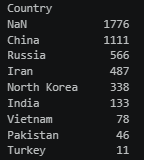

In [3]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. ⚙️ 데이터 로드 (경로는 질문자님의 파일 위치에 맞게 수정 가능)
cot_df = pd.read_csv('./midterm/cot_나라4개합친거.csv')
mi_df = pd.read_csv('./midterm/group_technique_country_final.csv')

# 2. 🌍 COT 데이터의 'State_sponsor' 국가 이름 표준화
name_mapping = {
    'Russian Federation': 'Russia',
    'Iran (Islamic Republic of)': 'Iran',
    "Korea (Democratic People's Republic of)": 'North Korea',
    'Korea (Republic of)': 'South Korea',
}
cot_df['State_sponsor'] = cot_df['State_sponsor'].replace(name_mapping)

# 3. 🔤 결측치 제거 및 텍스트 벡터화
cot_corpus = cot_df['Description'].fillna('').astype(str).tolist()
mi_corpus = mi_df['relationship_description'].fillna('').astype(str).tolist()

vectorizer = TfidfVectorizer(stop_words='english')
vectorizer.fit(cot_corpus + mi_corpus)

cot_matrix = vectorizer.transform(cot_corpus)
mi_matrix = vectorizer.transform(mi_corpus)

# 4. ⚡ 코사인 유사도 연산 (바둑판 매트릭스 생성)
sim_matrix = cosine_similarity(cot_matrix, mi_matrix)

# =====================================================================
# 5. 🎯 [그룹 기준 매칭] 그룹(group_id)별 유사도 총합을 기준으로 결측치 채우기
# =====================================================================
# 먼저 기존 Country 컬럼의 데이터를 그대로 복사하여 새로운 'Final_Country' 컬럼을 생성합니다.
mi_df['Final_Country'] = mi_df['Country']

# group_id를 기준으로 데이터프레임의 행 인덱스들을 그룹화합니다.
group_indices = mi_df.groupby('group_id').groups

for group_id, idx_list in group_indices.items():
    # 5-1. 해당 그룹 내의 행들 중 'Final_Country'가 결측치(NaN)인 행들의 인덱스만 추출
    nan_rows = [idx for idx in idx_list if pd.isna(mi_df.at[idx, 'Final_Country'])]
    
    # 만약 그룹 내에 채워야 할 결측치가 하나도 없다면 다음 그룹으로 넘어갑니다.
    if not nan_rows:
        continue
        
    # 5-2. 그룹에 속한 모든 행의 유사도 벡터를 더해 그룹을 대표하는 누적 점수 계산
    group_sim_vector = sim_matrix[:, idx_list].sum(axis=1)
    
    # 5-3. 가장 높은 누적 유사도 점수를 가진 COT 문서의 인덱스와 점수 확인
    best_cot_idx = np.argmax(group_sim_vector)
    best_score = group_sim_vector[best_cot_idx]
    
    # 5-4. 단어가 1개라도 겹쳐 유사도 점수가 0보다 큰 경우에만 국가 매칭 진행
    if best_score > 0:
        matched_country = cot_df.iloc[best_cot_idx]['State_sponsor']
        
        # ⚠️ 중요: 기존 값이 있던 행은 유지하고, 결측치(NaN)였던 행들만 동일 국가 이름으로 통일
        for idx in nan_rows:
            mi_df.at[idx, 'Final_Country'] = matched_country

# =====================================================================
# 6. 🎉 최종 결과 확인 및 파일 저장
# =====================================================================
print("=== 🤖 그룹 기반 국가 일치 및 결측치 유사도 매칭 완료! ===")
print("\n[원본 Country 컬럼 분포]")
print(mi_df['Country'].value_counts(dropna=False))

print("\n[그룹 내 국가를 통일하여 채운 Final_Country 컬럼 분포]")
print(mi_df['Final_Country'].value_counts(dropna=False))

# UTF-8 인코딩으로 깨짐 없이 안전하게 저장
mi_df.to_csv('group_technique_n.csv', index=False, encoding='utf-8-sig')
print("\n💾 최종 결과가 'group_technique_n.csv' 파일로 저장되었습니다.")

=== 🤖 그룹 기반 국가 일치 및 결측치 유사도 매칭 완료! ===

[원본 Country 컬럼 분포]
Country
NaN            1776
China          1111
Russia          566
Iran            487
North Korea     338
India           133
Vietnam          78
Pakistan         46
Turkey           11
Name: count, dtype: int64

[그룹 내 국가를 통일하여 채운 Final_Country 컬럼 분포]
Final_Country
China          1665
Russia         1153
Iran            770
North Korea     690
India           133
Vietnam          78
Pakistan         46
Turkey           11
Name: count, dtype: int64

💾 최종 결과가 'group_technique_n.csv' 파일로 저장되었습니다.
